# TASK 1: Analyse Data with Spark SQL

In [1]:
!pip install pyspark

In [2]:
from pyspark import SparkConf, SparkContext
from pyspark.sql import SparkSession, SQLContext
spark = SparkSession.builder.master("local[2]").appName("Police").getOrCreate()
sc = spark.sparkContext

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/01/30 04:47:35 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


**Imorting libraries**

In [3]:
from pyspark.sql.functions import *
from pyspark.sql.types import *
from pyspark.sql.window import Window


import os, glob, zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.mllib.evaluation import MulticlassMetrics
from pyspark.ml.classification import NaiveBayes, LogisticRegression


**Loading all CSV files**

In [4]:
police_data = "/kaggle/input/assignment2/Assignment 2/Police data"

crime_df = (
    spark.read
         .option("header", True)
         .option("inferSchema", True)
         .csv(f"{police_data}/20*/*.csv")
)

crime_df.createOrReplaceTempView("Crimesdf")

print("Rows (raw_data):", crime_df.count())
crime_df.printSchema()

Rows (raw_data): 800899
root
 |-- Crime ID: string (nullable = true)
 |-- Month: timestamp (nullable = true)
 |-- Reported by: string (nullable = true)
 |-- Falls within: string (nullable = true)
 |-- Longitude: double (nullable = true)
 |-- Latitude: double (nullable = true)
 |-- Location: string (nullable = true)
 |-- LSOA code: string (nullable = true)
 |-- LSOA name: string (nullable = true)
 |-- Crime type: string (nullable = true)
 |-- Last outcome category: string (nullable = true)
 |-- Context: string (nullable = true)



In [5]:
spark.sql("""
SELECT *
FROM Crimesdf
LIMIT 5
""").show(truncate=False)

+----------------------------------------------------------------+-------------------+----------------------+----------------------+---------+---------+-------------------------+---------+--------------------------+-------------------------+---------------------------------------------+-------+
|Crime ID                                                        |Month              |Reported by           |Falls within          |Longitude|Latitude |Location                 |LSOA code|LSOA name                 |Crime type               |Last outcome category                        |Context|
+----------------------------------------------------------------+-------------------+----------------------+----------------------+---------+---------+-------------------------+---------+--------------------------+-------------------------+---------------------------------------------+-------+
|60fdbf428bd2eba478af7f2f6ba9619f7cced33d070128a7b8aa82d78daf8186|2024-07-01 00:00:00|Hampshire Constabulary|Ham

In [6]:
spark.sql("""
SELECT `Crime type`, COUNT(*) AS count
FROM Crimesdf
GROUP BY `Crime type`
ORDER BY count DESC
""").show(20, truncate=False)

+----------------------------+------+
|Crime type                  |count |
+----------------------------+------+
|Violence and sexual offences|318145|
|Anti-social behaviour       |114260|
|Public order                |67091 |
|Shoplifting                 |64487 |
|Criminal damage and arson   |61638 |
|Other theft                 |49359 |
|Vehicle crime               |32490 |
|Burglary                    |28729 |
|Drugs                       |23881 |
|Other crime                 |15729 |
|Bicycle theft               |8714  |
|Possession of weapons       |8125  |
|Robbery                     |4297  |
|Theft from the person       |3954  |
+----------------------------+------+



**Selecting only needed columns**

In [7]:
crime_df.createOrReplaceTempView("Crimesdf")

crime_df = spark.sql("""
SELECT
  to_date(concat(`Month`, '-01')) AS Month,
  `Reported by`                   AS Reported_by,
  Location                        AS Location,
  `Crime type`                    AS Crime_type
FROM Crimesdf
WHERE `Crime ID` IS NOT NULL
""")

print("\n--- Updated Info after dropping specified columns ---\n")
crime_df.printSchema()
print("Rows:", crime_df.count())
print("Columns:", len(crime_df.columns))
crime_df.show(5, truncate=False)

crime_df.createOrReplaceTempView("CrimesClean")


--- Updated Info after dropping specified columns ---

root
 |-- Month: date (nullable = true)
 |-- Reported_by: string (nullable = true)
 |-- Location: string (nullable = true)
 |-- Crime_type: string (nullable = true)



Rows: 686639
Columns: 4
+----------+----------------------+-------------------------+-------------------------+
|Month     |Reported_by           |Location                 |Crime_type               |
+----------+----------------------+-------------------------+-------------------------+
|2024-07-01|Hampshire Constabulary|On or near Stanfield     |Other theft              |
|2024-07-01|Hampshire Constabulary|On or near Huntsmoor Road|Criminal damage and arson|
|2024-07-01|Hampshire Constabulary|On or near Huntsmoor Road|Public order             |
|2024-07-01|Hampshire Constabulary|On or near Supermarket   |Shoplifting              |
|2024-07-01|Hampshire Constabulary|On or near Newchurch Road|Vehicle crime            |
+----------+----------------------+-------------------------+-------------------------+
only showing top 5 rows



In [8]:
crime_df.createOrReplaceTempView("CrimesClean")

crime_counts_table = spark.sql("""
SELECT
  Crime_type AS `Crime Type`,
  COUNT(*)   AS Count
FROM CrimesClean
GROUP BY Crime_type
ORDER BY Count DESC
""")

print("Table of Crime Types and their Counts:")
crime_counts_table.show(50, truncate=False)

Table of Crime Types and their Counts:


+----------------------------+------+
|Crime Type                  |Count |
+----------------------------+------+
|Violence and sexual offences|318145|
|Public order                |67091 |
|Shoplifting                 |64487 |
|Criminal damage and arson   |61638 |
|Other theft                 |49359 |
|Vehicle crime               |32490 |
|Burglary                    |28729 |
|Drugs                       |23881 |
|Other crime                 |15729 |
|Bicycle theft               |8714  |
|Possession of weapons       |8125  |
|Robbery                     |4297  |
|Theft from the person       |3954  |
+----------------------------+------+



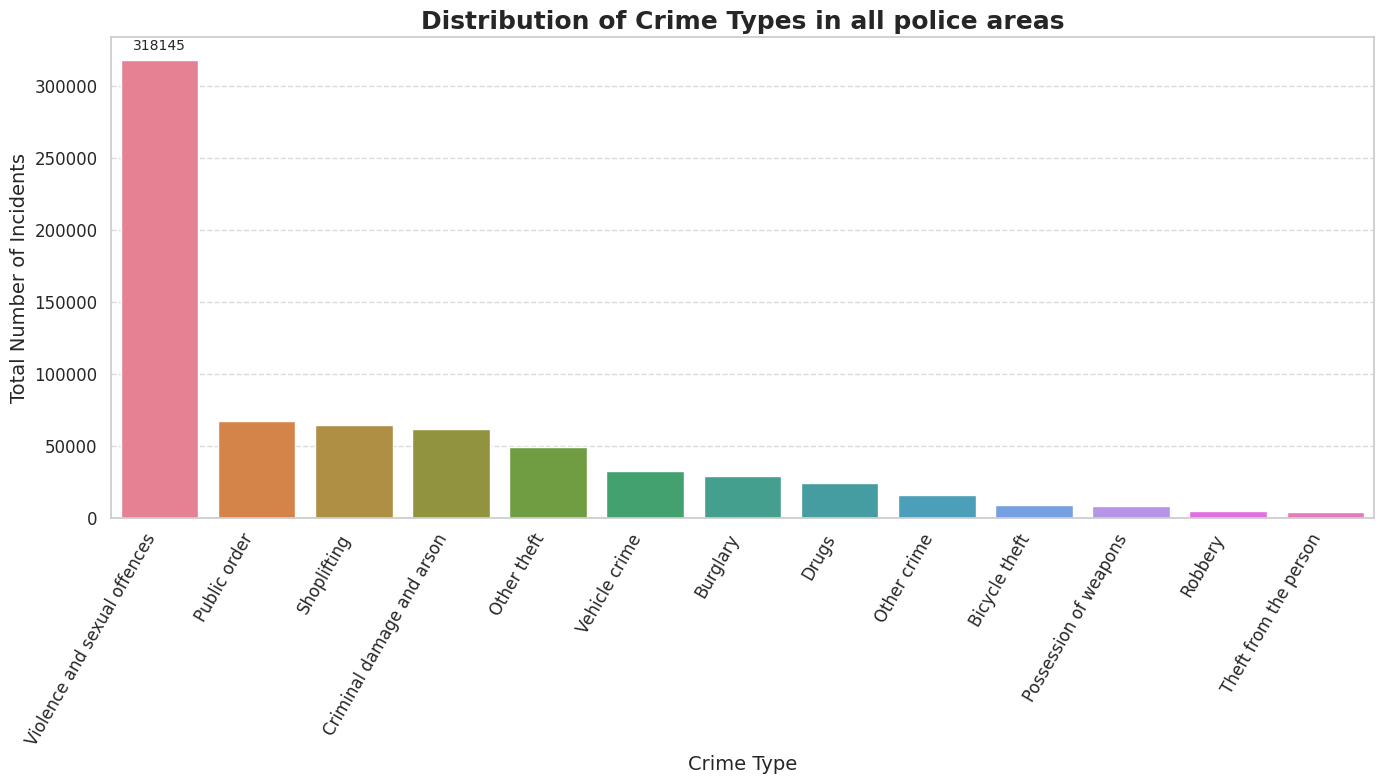

In [9]:
crime_counts_pd = crime_counts_table.toPandas()

sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 8))

ax = sns.barplot(
    data=crime_counts_pd,
    x="Crime Type",
    y="Count",
    hue="Crime Type",
    legend=False
)

ax.bar_label(ax.containers[0], fmt="%d", label_type="edge", fontsize=10, padding=5)

plt.title("Distribution of Crime Types in all police areas", fontsize=18, fontweight="bold")
plt.xlabel("Crime Type", fontsize=14)
plt.ylabel("Total Number of Incidents", fontsize=14)
plt.xticks(rotation=60, ha="right", fontsize=12)
plt.yticks(fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

In [10]:
crime_df.createOrReplaceTempView("CrimesClean")

police_areas = spark.sql("""
SELECT DISTINCT
  Reported_by AS `Police Area`
FROM CrimesClean
ORDER BY `Police Area`
""")

print("Unique Police Areas:")
police_areas.show(truncate=False)

Unique Police Areas:


+----------------------+
|Police Area           |
+----------------------+
|Cheshire Constabulary |
|Hampshire Constabulary|
|North Yorkshire Police|
|Wiltshire Police      |
+----------------------+



**Crimes count by Police Area and Crime Type**

In [11]:
crime_df.createOrReplaceTempView("CrimesClean")

df_top_crimes_by_area = spark.sql("""
WITH counts AS (
  SELECT
    Reported_by AS `Police Area`,
    Crime_type  AS `Crime Type`,
    COUNT(*)    AS Count
  FROM CrimesClean
  GROUP BY Reported_by, Crime_type
),
ranked AS (
  SELECT
    *,
    ROW_NUMBER() OVER (PARTITION BY `Police Area` ORDER BY Count DESC) AS rnk
  FROM counts
)
SELECT `Police Area`, `Crime Type`, Count
FROM ranked
WHERE rnk <= 5
ORDER BY `Police Area`, Count DESC
""")

print("--- Top 5 Crimes by Police Area ---")
df_top_crimes_by_area.show(50, truncate=False)

--- Top 5 Crimes by Police Area ---


+----------------------+----------------------------+------+
|Police Area           |Crime Type                  |Count |
+----------------------+----------------------------+------+
|Cheshire Constabulary |Violence and sexual offences|82731 |
|Cheshire Constabulary |Public order                |18366 |
|Cheshire Constabulary |Criminal damage and arson   |12866 |
|Cheshire Constabulary |Shoplifting                 |12295 |
|Cheshire Constabulary |Other theft                 |11303 |
|Hampshire Constabulary|Violence and sexual offences|149472|
|Hampshire Constabulary|Public order                |33346 |
|Hampshire Constabulary|Shoplifting                 |32057 |
|Hampshire Constabulary|Criminal damage and arson   |28513 |
|Hampshire Constabulary|Other theft                 |24269 |
|North Yorkshire Police|Violence and sexual offences|46643 |
|North Yorkshire Police|Shoplifting                 |11701 |
|North Yorkshire Police|Criminal damage and arson   |10733 |
|North Yorkshire Police|

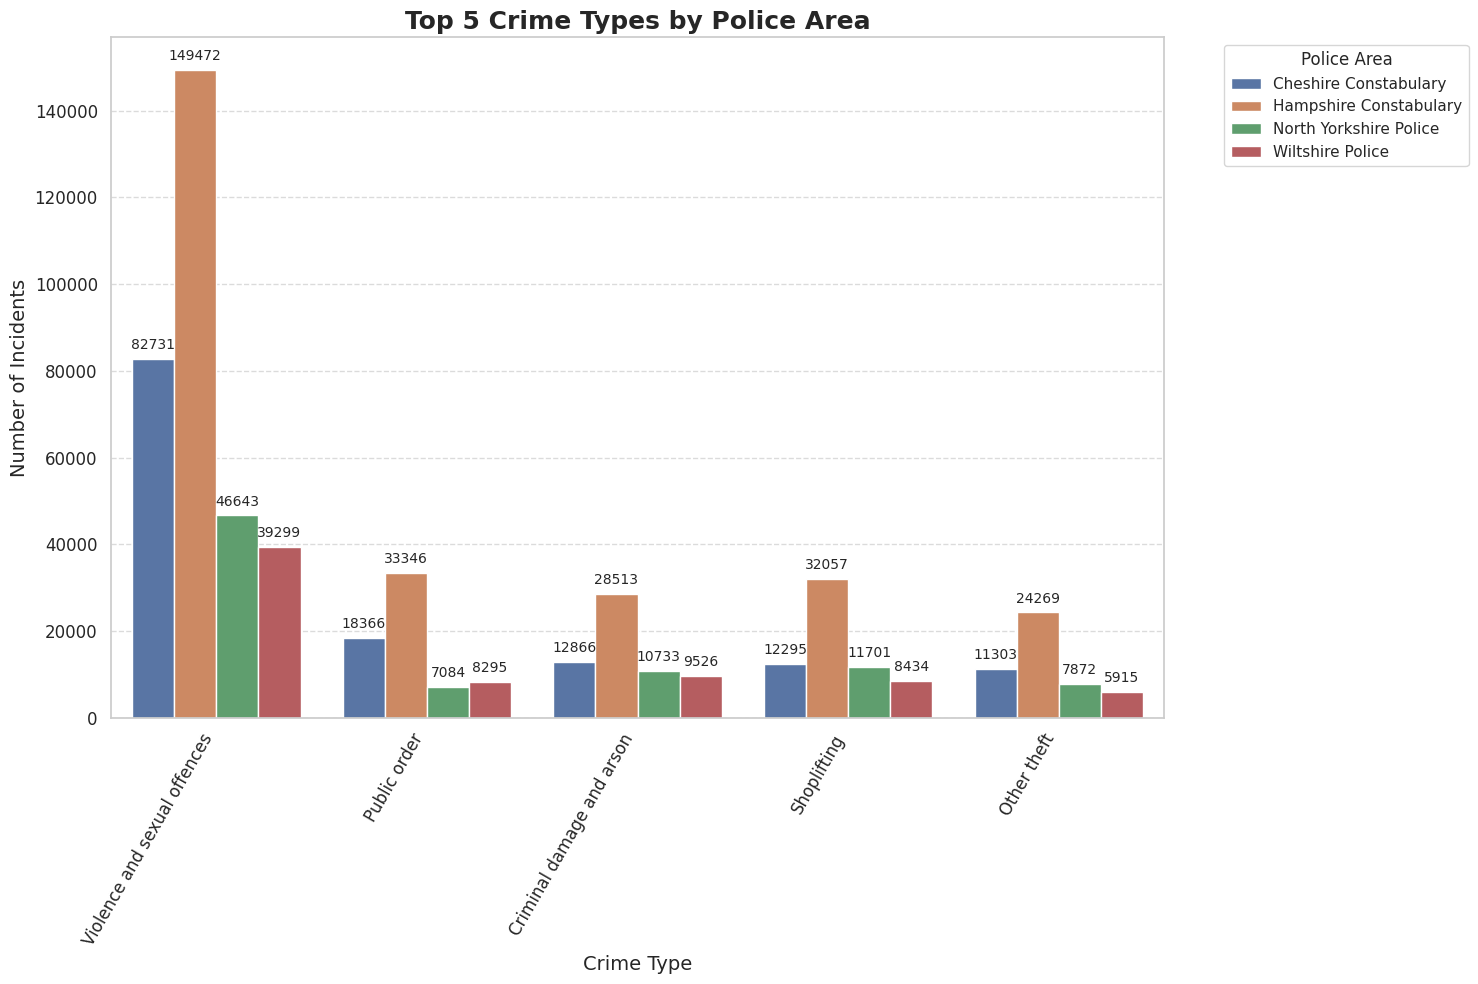

In [12]:
top_crimes_pd = df_top_crimes_by_area.toPandas()

sns.set_theme(style="whitegrid")
plt.figure(figsize=(15, 10))

ax = sns.barplot(
    data=top_crimes_pd,
    x="Crime Type",
    y="Count",
    hue="Police Area"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", label_type="edge", fontsize=10, padding=5)

plt.title("Top 5 Crime Types by Police Area", fontsize=18, fontweight="bold")
plt.xlabel("Crime Type", fontsize=14)
plt.ylabel("Number of Incidents", fontsize=14)
plt.xticks(rotation=60, ha="right", fontsize=12)
plt.yticks(fontsize=12)
plt.legend(title="Police Area", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

**Donut charts of Top 5 crimes + other per police area**

In [13]:
crime_df.createOrReplaceTempView("CrimesClean")

composition_top5_other = spark.sql("""
WITH counts AS (
  SELECT
    Reported_by,
    Crime_type,
    COUNT(*) AS Count
  FROM CrimesClean
  GROUP BY Reported_by, Crime_type
),
totals AS (
  SELECT
    Reported_by,
    SUM(Count) AS Total
  FROM counts
  GROUP BY Reported_by
),
comp AS (
  SELECT
    c.Reported_by,
    c.Crime_type,
    (c.Count / t.Total) * 100 AS Percentage
  FROM counts c
  JOIN totals t
    ON c.Reported_by = t.Reported_by
),
ranked AS (
  SELECT
    *,
    ROW_NUMBER() OVER (PARTITION BY Reported_by ORDER BY Percentage DESC) AS rn
  FROM comp
)
SELECT
  Reported_by,
  CASE WHEN rn <= 5 THEN Crime_type ELSE 'Other' END AS Crime_Group,
  SUM(Percentage) AS Percentage
FROM ranked
GROUP BY Reported_by, CASE WHEN rn <= 5 THEN Crime_type ELSE 'Other' END
ORDER BY Reported_by, Percentage DESC
""")

composition_top5_other.show(30, truncate=False)

+----------------------+----------------------------+------------------+
|Reported_by           |Crime_Group                 |Percentage        |
+----------------------+----------------------------+------------------+
|Cheshire Constabulary |Violence and sexual offences|50.16340959114254 |
|Cheshire Constabulary |Other                       |16.590772663606653|
|Cheshire Constabulary |Public order                |11.13610594034792 |
|Cheshire Constabulary |Criminal damage and arson   |7.801216325194181 |
|Cheshire Constabulary |Shoplifting                 |7.454994148784584 |
|Cheshire Constabulary |Other theft                 |6.853501330924128 |
|Hampshire Constabulary|Violence and sexual offences|45.185552425059555|
|Hampshire Constabulary|Other                       |19.086990169167702|
|Hampshire Constabulary|Public order                |10.0805330173279  |
|Hampshire Constabulary|Shoplifting                 |9.690866878680517 |
|Hampshire Constabulary|Criminal damage and arson  

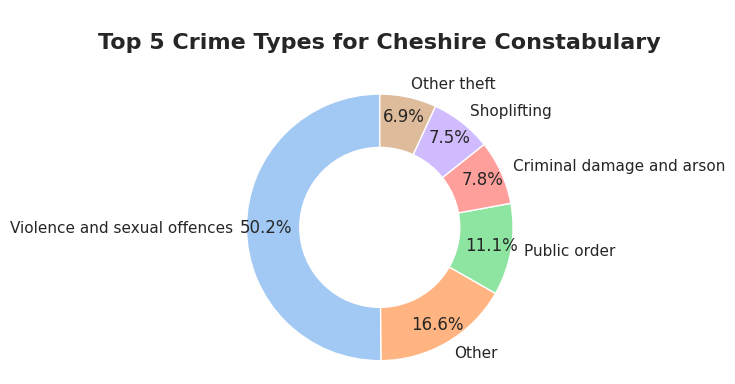

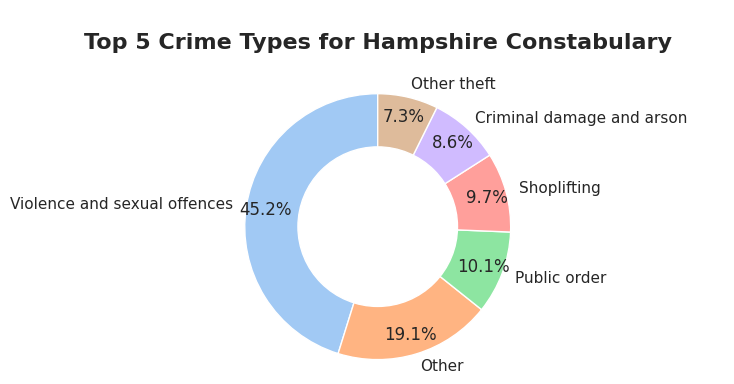

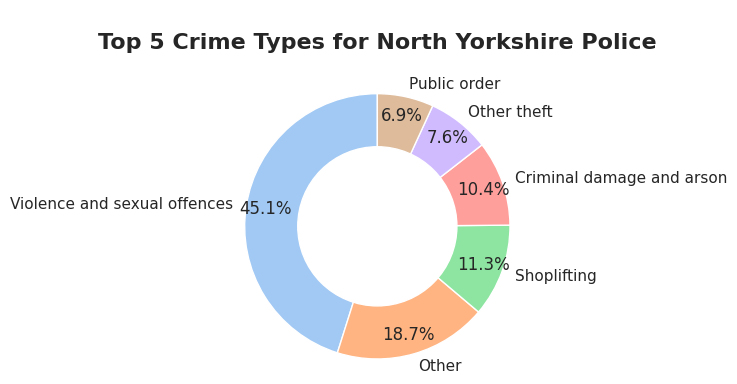

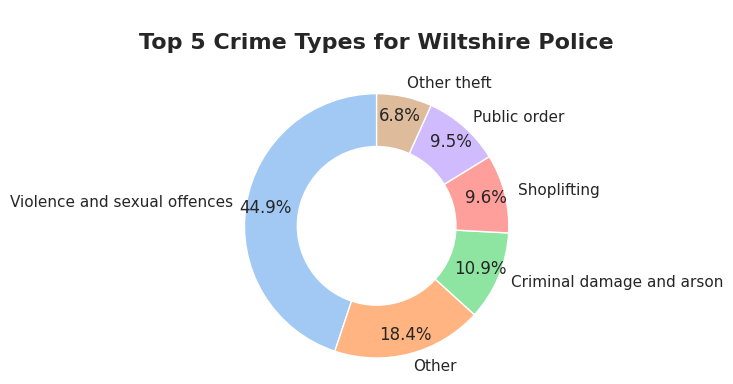

In [14]:
from pyspark.sql import functions as F

areas = [r["Reported_by"] for r in composition_top5_other.select("Reported_by").distinct().collect()]

for area in areas:
    plot_df = (
        composition_top5_other
        .filter(F.col("Reported_by") == area)
        .orderBy(F.desc("Percentage"))
        .select(
            F.col("Crime_Group").alias("Crime type"),
            F.col("Percentage")
        )
        .toPandas()
    )

    sns.set_theme(style="whitegrid")
    plt.figure(figsize=(8, 4))

    wedges, texts, autotexts = plt.pie(
        plot_df["Percentage"],
        labels=plot_df["Crime type"],
        autopct="%1.1f%%",
        startangle=90,
        pctdistance=0.85,
        colors=sns.color_palette("pastel", n_colors=len(plot_df))
    )

    # donut hole
    centre_circle = plt.Circle((0, 0), 0.60, fc="white")
    fig = plt.gcf()
    fig.gca().add_artist(centre_circle)

    plt.title(f"\nTop 5 Crime Types for {area}\n", fontsize=16, fontweight="bold")
    plt.axis("equal")
    plt.tight_layout()
    plt.show()

In [15]:
crime_df.createOrReplaceTempView("CrimesClean")

df_monthly_crime_counts = spark.sql("""
SELECT
  Month,
  Reported_by,
  COUNT(*) AS Crime_Count
FROM CrimesClean
GROUP BY Month, Reported_by
ORDER BY Month, Reported_by
""")

print("--- Monthly Crime Counts by Police Area (First 10 Rows) ---")
df_monthly_crime_counts.show(10, truncate=False)

--- Monthly Crime Counts by Police Area (First 10 Rows) ---


+----------+----------------------+-----------+
|Month     |Reported_by           |Crime_Count|
+----------+----------------------+-----------+
|2023-05-01|Cheshire Constabulary |6813       |
|2023-05-01|Hampshire Constabulary|13825      |
|2023-05-01|North Yorkshire Police|4472       |
|2023-05-01|Wiltshire Police      |3559       |
|2023-06-01|Cheshire Constabulary |6887       |
|2023-06-01|Hampshire Constabulary|13857      |
|2023-06-01|North Yorkshire Police|4068       |
|2023-06-01|Wiltshire Police      |3125       |
|2023-07-01|Cheshire Constabulary |6331       |
|2023-07-01|Hampshire Constabulary|13722      |
+----------+----------------------+-----------+
only showing top 10 rows



**Plotting monthly crime trends by police area**

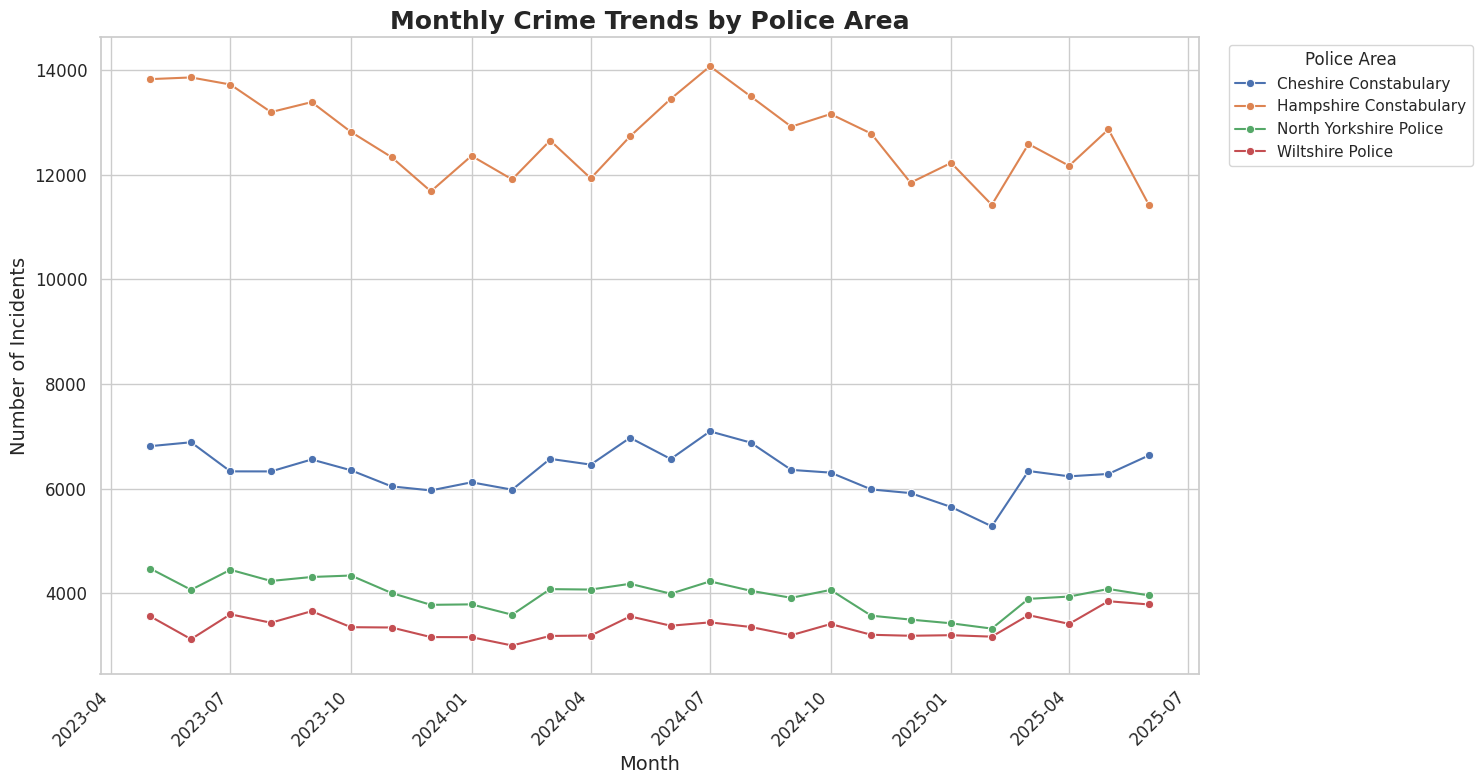

In [16]:
df_monthly_crime_counts_pd = df_monthly_crime_counts.toPandas()

df_monthly_crime_counts_pd["Month"] = pd.to_datetime(df_monthly_crime_counts_pd["Month"])
df_monthly_crime_counts_pd = df_monthly_crime_counts_pd.sort_values("Month")

sns.set_theme(style="whitegrid")
plt.figure(figsize=(15, 8))

sns.lineplot(
    data=df_monthly_crime_counts_pd,
    x="Month",
    y="Crime_Count",
    hue="Reported_by",
    marker="o"
)
plt.title("Monthly Crime Trends by Police Area", fontsize=18, fontweight="bold")
plt.xlabel("Month", fontsize=14)
plt.ylabel("Number of Incidents", fontsize=14)
plt.xticks(rotation=45, ha="right", fontsize=12)
plt.yticks(fontsize=12)
plt.legend(title="Police Area", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Crime count for each month (sum of all areas)**

In [17]:
df_monthly_crime_counts.createOrReplaceTempView("MonthlyCrimeCounts")

df_total_monthly_crime = spark.sql("""
SELECT
  Month,
  SUM(Crime_Count) AS Total_Crime_Count
FROM MonthlyCrimeCounts
GROUP BY Month
ORDER BY Month
""")

print("--- Total Monthly Crime Counts (All Areas Combined, First 5 Rows) ---")
df_total_monthly_crime.show(5, truncate=False)

--- Total Monthly Crime Counts (All Areas Combined, First 5 Rows) ---


+----------+-----------------+
|Month     |Total_Crime_Count|
+----------+-----------------+
|2023-05-01|28669            |
|2023-06-01|27937            |
|2023-07-01|28104            |
|2023-08-01|27201            |
|2023-09-01|27917            |
+----------+-----------------+
only showing top 5 rows



**Plotting monthly crime trends for total crimes**

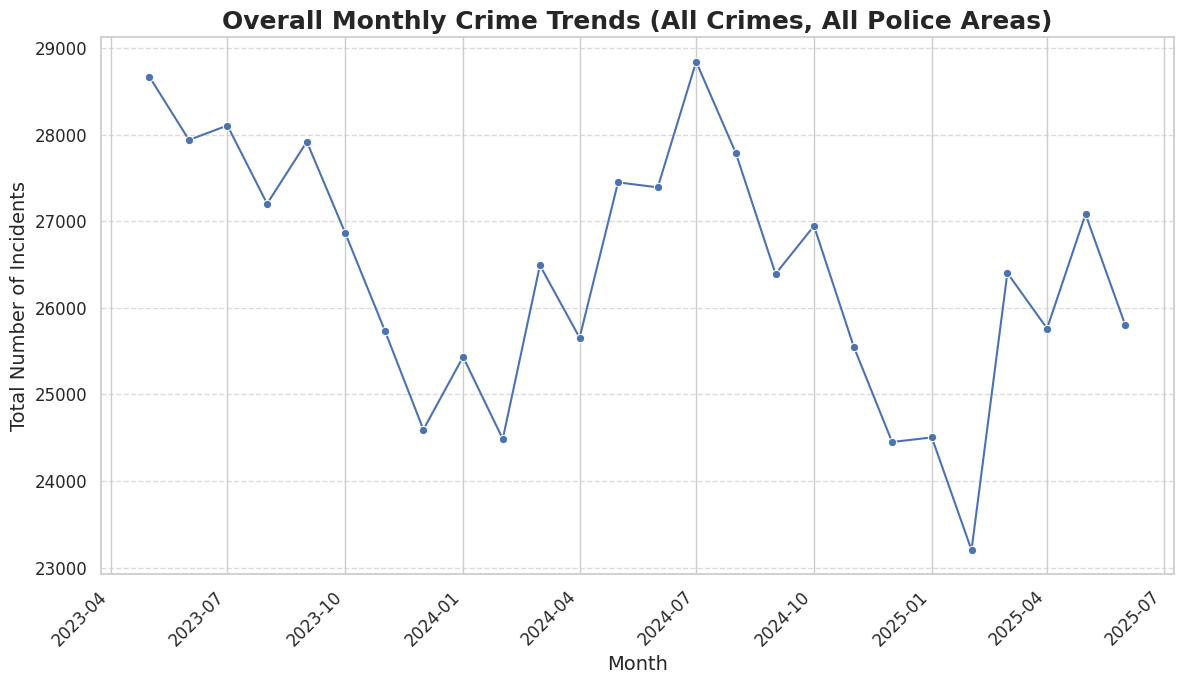

In [18]:
df_total_monthly_crime_pd = df_total_monthly_crime.toPandas()

# Ensure Month sorts correctly (Spark Month is usually date already, but pandas may treat it as object)
df_total_monthly_crime_pd["Month"] = pd.to_datetime(df_total_monthly_crime_pd["Month"])
df_total_monthly_crime_pd = df_total_monthly_crime_pd.sort_values("Month")

sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 7))

sns.lineplot(
    data=df_total_monthly_crime_pd,
    x="Month",
    y="Total_Crime_Count",
    marker="o"
)

plt.title("Overall Monthly Crime Trends (All Crimes, All Police Areas)", fontsize=18, fontweight="bold")
plt.xlabel("Month", fontsize=14)
plt.ylabel("Total Number of Incidents", fontsize=14)
plt.xticks(rotation=45, ha="right", fontsize=12)
plt.yticks(fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

In [19]:
from pyspark.sql import functions as F

df_crime_counts_per_area = (
    crime_df
    .groupBy("Reported_by", "Crime_type")
    .count()
    .withColumnRenamed("count", "Count")
    .orderBy(F.desc("Count"))
)

print("--- Crime Counts per Police Area and Crime Type (First 5 Rows) ---")
df_crime_counts_per_area.show(5, truncate=False)


--- Crime Counts per Police Area and Crime Type (First 5 Rows) ---


+----------------------+----------------------------+------+
|Reported_by           |Crime_type                  |Count |
+----------------------+----------------------------+------+
|Hampshire Constabulary|Violence and sexual offences|149472|
|Cheshire Constabulary |Violence and sexual offences|82731 |
|North Yorkshire Police|Violence and sexual offences|46643 |
|Wiltshire Police      |Violence and sexual offences|39299 |
|Hampshire Constabulary|Public order                |33346 |
+----------------------+----------------------------+------+
only showing top 5 rows



In [20]:
if "count" in df_crime_counts_per_area.columns and "Count" not in df_crime_counts_per_area.columns:
    df_crime_counts_per_area = df_crime_counts_per_area.withColumnRenamed("count", "Count")

total_crimes_per_area = (
    df_crime_counts_per_area
    .groupBy("Reported_by")
    .agg(F.sum("Count").alias("Total_Crimes"))
    .orderBy(F.desc("Total_Crimes"))
)

print("--- Total Crimes per Police Area ---")
total_crimes_per_area.show(5, truncate=False)

--- Total Crimes per Police Area ---


+----------------------+------------+
|Reported_by           |Total_Crimes|
+----------------------+------------+
|Hampshire Constabulary|330796      |
|Cheshire Constabulary |164923      |
|North Yorkshire Police|103350      |
|Wiltshire Police      |87570       |
+----------------------+------------+



In [21]:
if "count" in df_crime_counts_per_area.columns and "Count" not in df_crime_counts_per_area.columns:
    df_crime_counts_per_area = df_crime_counts_per_area.withColumnRenamed("count", "Count")

df_crime_percentage_composition = (
    df_crime_counts_per_area
    .join(total_crimes_per_area, on="Reported_by", how="left")
    .withColumn("Percentage", (F.col("Count") / F.col("Total_Crimes")) * 100)
)

print("--- Crime Type Percentage Composition (First 5 Rows) ---")
df_crime_percentage_composition.show(5, truncate=False)

--- Crime Type Percentage Composition (First 5 Rows) ---


+----------------------+-------------+-----+------------+------------------+
|Reported_by           |Crime_type   |Count|Total_Crimes|Percentage        |
+----------------------+-------------+-----+------------+------------------+
|Hampshire Constabulary|Other theft  |24269|330796      |7.336545786527044 |
|Hampshire Constabulary|Robbery      |2363 |330796      |0.7143375373341878|
|Hampshire Constabulary|Vehicle crime|18719|330796      |5.658774592195794 |
|Hampshire Constabulary|Shoplifting  |32057|330796      |9.690866878680517 |
|Hampshire Constabulary|Bicycle theft|3556 |330796      |1.0749827688363827|
+----------------------+-------------+-----+------------+------------------+
only showing top 5 rows



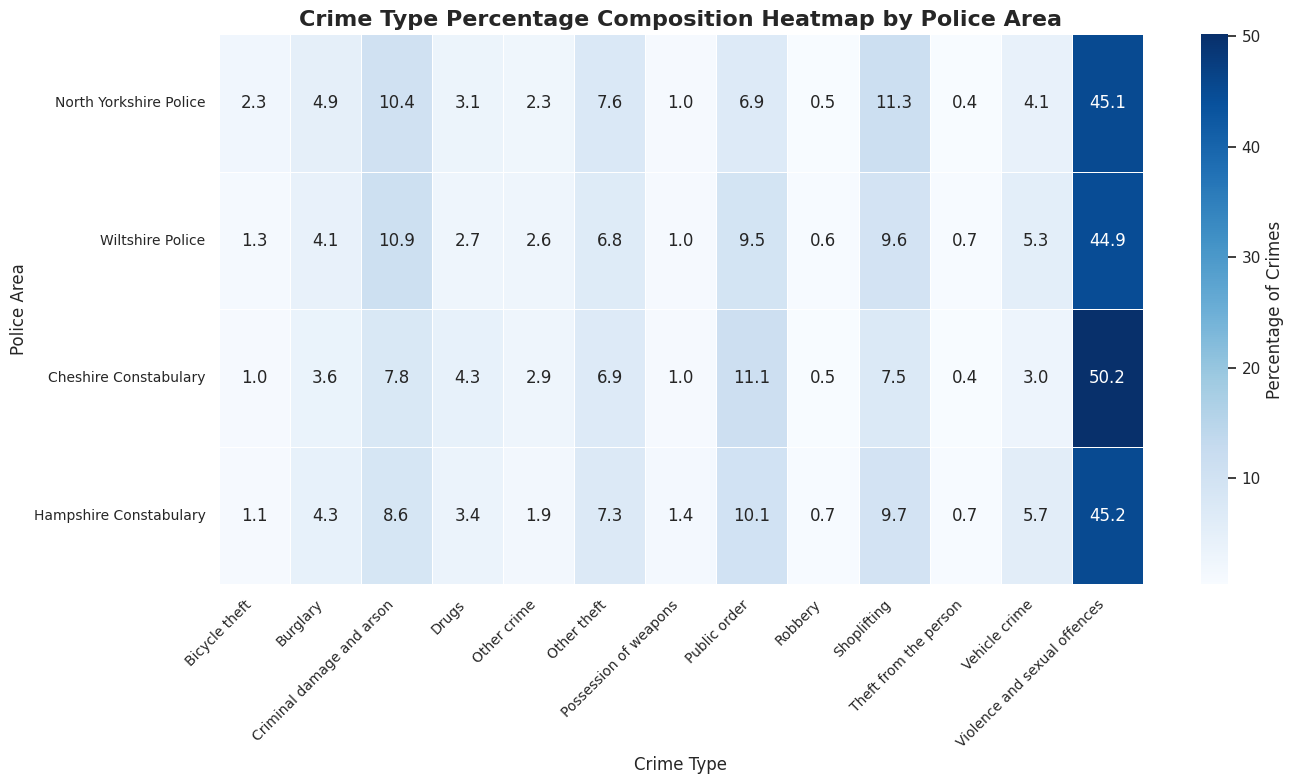

In [22]:
df_heatmap_spark = (
    df_crime_percentage_composition
    .groupBy("Reported_by")
    .pivot("Crime_type")
    .agg(F.first("Percentage"))
    .na.fill(0)
)

df_pivot_heatmap = df_heatmap_spark.toPandas().set_index("Reported_by")

sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 8))

sns.heatmap(
    df_pivot_heatmap,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Percentage of Crimes"}
)

plt.title("Crime Type Percentage Composition Heatmap by Police Area", fontsize=16, fontweight="bold")
plt.xlabel("Crime Type", fontsize=12)
plt.ylabel("Police Area", fontsize=12)
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()

# TASK 2: Implement machine learning algorithms for data analytics

In [23]:
titanic_df= pd.read_csv("/kaggle/input/assignment2/Assignment 2/TitanicData1.csv")

In [24]:
print(titanic_df.head())

   PassengerId  Pclass                                               Name  \
0            1       3                            Braund, Mr. Owen Harris   
1            2       1  Cumings, Mrs. John Bradley (Florence Briggs Th...   
2            3       3                             Heikkinen, Miss. Laina   
3            4       1       Futrelle, Mrs. Jacques Heath (Lily May Peel)   
4            5       3                           Allen, Mr. William Henry   

      Sex   Age  SibSp  Parch            Ticket     Fare Cabin Embarked  \
0    male  22.0      1      0         A/5 21171   7.2500   NaN        S   
1  female  38.0      1      0          PC 17599  71.2833   C85        C   
2  female  26.0      0      0  STON/O2. 3101282   7.9250   NaN        S   
3  female  35.0      1      0            113803  53.1000  C123        S   
4    male  35.0      0      0            373450   8.0500   NaN        S   

   Survived  
0         0  
1         1  
2         1  
3         1  
4         0  


In [25]:
featurelist = titanic_df.columns.tolist()
print (featurelist)

['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked', 'Survived']


In [26]:
titanic_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Pclass       891 non-null    int64  
 2   Name         891 non-null    object 
 3   Sex          891 non-null    object 
 4   Age          714 non-null    float64
 5   SibSp        891 non-null    int64  
 6   Parch        891 non-null    int64  
 7   Ticket       891 non-null    object 
 8   Fare         891 non-null    float64
 9   Cabin        204 non-null    object 
 10  Embarked     889 non-null    object 
 11  Survived     891 non-null    int64  
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


**Handling Missing Values**

In [27]:
print("\nMissing values in each column:")
print(titanic_df.isnull().sum())


Missing values in each column:
PassengerId      0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
Survived         0
dtype: int64


In [28]:
titanic_df['Age'] = titanic_df['Age'].fillna(titanic_df['Age'].mean()).astype(int)

In [29]:
titanic_df['Embarked'].fillna(titanic_df['Embarked'].mode()[0], inplace=True)

/tmp/ipykernel_55/2728790306.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  titanic_df['Embarked'].fillna(titanic_df['Embarked'].mode()[0], inplace=True)


In [30]:
print("\nMissing values in each column:")
print(titanic_df.isnull().sum())


Missing values in each column:
PassengerId      0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
Survived         0
dtype: int64


**Data Cleaning & Converting Categorical Variables**

In [31]:
titanic_df.drop(columns=['PassengerId','Name','Ticket','Cabin'], inplace=True)

In [32]:
print(titanic_df.head())
titanic_df.info()

   Pclass     Sex  Age  SibSp  Parch     Fare Embarked  Survived
0       3    male   22      1      0   7.2500        S         0
1       1  female   38      1      0  71.2833        C         1
2       3  female   26      0      0   7.9250        S         1
3       1  female   35      1      0  53.1000        S         1
4       3    male   35      0      0   8.0500        S         0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Pclass    891 non-null    int64  
 1   Sex       891 non-null    object 
 2   Age       891 non-null    int64  
 3   SibSp     891 non-null    int64  
 4   Parch     891 non-null    int64  
 5   Fare      891 non-null    float64
 6   Embarked  891 non-null    object 
 7   Survived  891 non-null    int64  
dtypes: float64(1), int64(5), object(2)
memory usage: 55.8+ KB


In [33]:
titanic_df['Sex'] = titanic_df['Sex'].map({'male': 1, 'female': 0})
titanic_df['Embarked'] = titanic_df['Embarked'].map({'C': 0, 'S': 1, 'Q': 2})
print(titanic_df.head(5))

   Pclass  Sex  Age  SibSp  Parch     Fare  Embarked  Survived
0       3    1   22      1      0   7.2500         1         0
1       1    0   38      1      0  71.2833         0         1
2       3    0   26      0      0   7.9250         1         1
3       1    0   35      1      0  53.1000         1         1
4       3    1   35      0      0   8.0500         1         0


**Correlation Matrix of Selected Titanic Features**

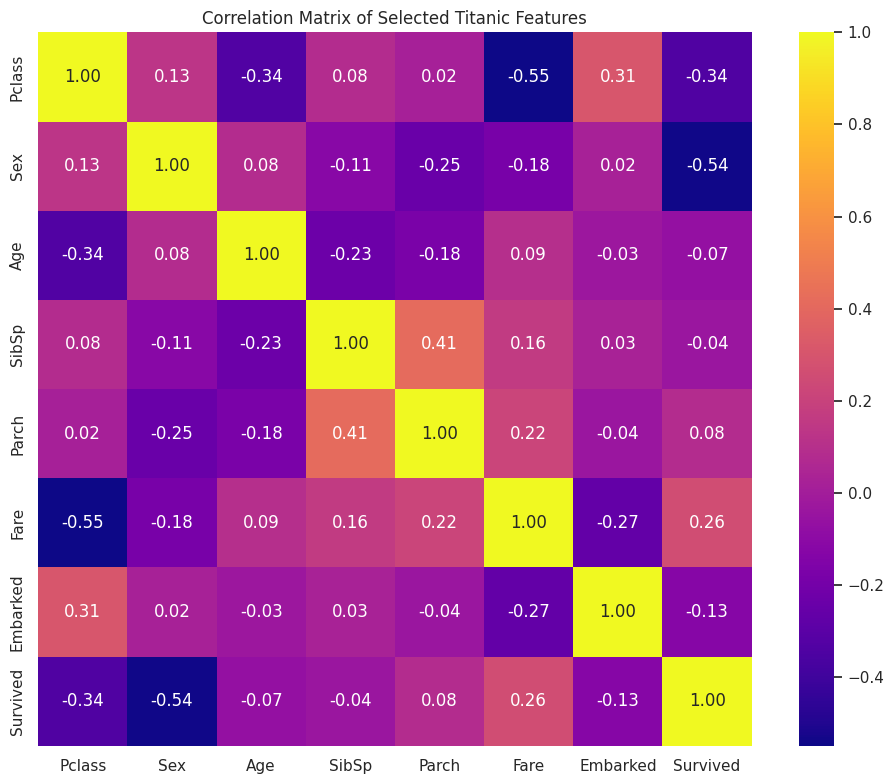

In [34]:
plt.figure(figsize=(10, 8))
sns.heatmap(
    titanic_df.corr(),
    annot=True,
    cmap="plasma",
    fmt=".2f",
    square=True
)

plt.title("Correlation Matrix of Selected Titanic Features")
plt.tight_layout()
plt.show()

**PYSPARK Session**

In [35]:
from pyspark.sql import SparkSession
spark = SparkSession.builder.appName("Titanic").getOrCreate()
spark_titanic_df = spark.createDataFrame(titanic_df)
spark_titanic_df.show(5)
spark_titanic_df.printSchema()

26/01/30 04:48:51 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.


+------+---+---+-----+-----+-------+--------+--------+
|Pclass|Sex|Age|SibSp|Parch|   Fare|Embarked|Survived|
+------+---+---+-----+-----+-------+--------+--------+
|     3|  1| 22|    1|    0|   7.25|       1|       0|
|     1|  0| 38|    1|    0|71.2833|       0|       1|
|     3|  0| 26|    0|    0|  7.925|       1|       1|
|     1|  0| 35|    1|    0|   53.1|       1|       1|
|     3|  1| 35|    0|    0|   8.05|       1|       0|
+------+---+---+-----+-----+-------+--------+--------+
only showing top 5 rows

root
 |-- Pclass: long (nullable = true)
 |-- Sex: long (nullable = true)
 |-- Age: long (nullable = true)
 |-- SibSp: long (nullable = true)
 |-- Parch: long (nullable = true)
 |-- Fare: double (nullable = true)
 |-- Embarked: long (nullable = true)
 |-- Survived: long (nullable = true)



**Feature Transformation**

In [36]:
from pyspark.ml.feature import VectorAssembler, StringIndexer

assembler = VectorAssembler(inputCols=["Pclass","Sex","Age","SibSp","Parch","Fare","Embarked"],
outputCol="features")
labelIndexer = StringIndexer(inputCol="Survived", outputCol="label")
data = labelIndexer.fit(spark_titanic_df).transform(spark_titanic_df)
data = assembler.transform(data)
final_data = data.select("features","label")
final_data.show(5)

+--------------------+-----+
|            features|label|
+--------------------+-----+
|[3.0,1.0,22.0,1.0...|  0.0|
|[1.0,0.0,38.0,1.0...|  1.0|
|[3.0,0.0,26.0,0.0...|  1.0|
|[1.0,0.0,35.0,1.0...|  1.0|
|[3.0,1.0,35.0,0.0...|  0.0|
+--------------------+-----+
only showing top 5 rows



**Adopting first Tukey’s method to identify the outliers**

Text(0.5, 1.0, 'Tukey Method Visualization: Age by Survival and Class')

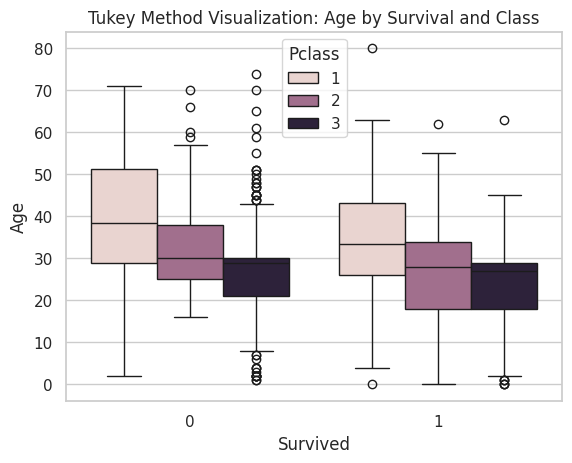

In [37]:
box_plot = plt.figure()
sns.boxplot(x='Survived', y='Age', hue='Pclass', data=titanic_df)
plt.title("Tukey Method Visualization: Age by Survival and Class")

In [38]:
titanic_df_1 = titanic_df[(titanic_df['Pclass']==3)&(titanic_df['Survived']==0)]

AsPerAge = np.percentile(titanic_df_1['Age'],[0,25,50,75,100])

IQR = AsPerAge[3]-AsPerAge[1]

upperAge = AsPerAge[3]+IQR*1.5

lowerAge = AsPerAge[3]-IQR*1.5

print (titanic_df_1.loc[(titanic_df_1['Age']>upperAge)|(titanic_df_1['Age']<lowerAge),'Age'])


7       2
14     14
16      2
24      8
50      7
       ..
824     2
850     4
851    74
852     9
873    47
Name: Age, Length: 66, dtype: int64


In [39]:
print (titanic_df_1['Age'])

0      22
4      35
5      29
7       2
12     20
       ..
882    22
884    25
885    39
888    29
890    32
Name: Age, Length: 372, dtype: int64


In [40]:
Q1 = titanic_df_1['Age'].quantile(0.25)
Q3 = titanic_df_1['Age'].quantile(0.75)

IQR = Q3-Q1
lowerAge = Q1-1.5*IQR
upperAge = Q1+1.5*IQR

outlier_values =  titanic_df_1.loc[(titanic_df_1['Age']<lowerAge)|(titanic_df_1['Age']>upperAge), 'Age'].unique()

titanic_df_1['Age'] = titanic_df_1['Age'].replace(list(outlier_values),20)

/tmp/ipykernel_55/3024176166.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  titanic_df_1['Age'] = titanic_df_1['Age'].replace(list(outlier_values),20)


In [41]:
print (titanic_df_1['Age'].describe())
print ("Min/Max:", titanic_df_1['Age'].min(),titanic_df_1['Age'].max())
print ("Any NaNs in Age?->",titanic_df_1['Age'].isna().any())
print ("Unique values sample:", titanic_df_1['Age'].unique()[:10])

count    372.000000
mean      23.932796
std        5.599220
min        8.000000
25%       20.000000
50%       24.000000
75%       29.000000
max       34.000000
Name: Age, dtype: float64
Min/Max: 8 34
Any NaNs in Age?-> False
Unique values sample: [22 20 29 14 31  8 21 18 28 11]


**Train test**

In [42]:
train_data, test_data = final_data.randomSplit([0.7, 0.3], seed=42)
print("Training set count:", train_data.count())
print("Test set count:", test_data.count())

Training set count: 636
Test set count: 255


In [43]:
nb = NaiveBayes(featuresCol="features", labelCol="label")
nb_model = nb.fit(train_data)
predictions_nb = nb_model.transform(test_data)
print("Naive Bayes predictions (features, label, prediction, probability):")
predictions_nb.select("features","label","prediction","probability").show(5)

Naive Bayes predictions (features, label, prediction, probability):
+--------------------+-----+----------+--------------------+
|            features|label|prediction|         probability|
+--------------------+-----+----------+--------------------+
|(7,[0,2,5],[1.0,2...|  1.0|       1.0|[2.02277122258059...|
|(7,[0,2,5],[1.0,3...|  1.0|       1.0|[9.87329178117151...|
|(7,[0,2,5],[1.0,4...|  1.0|       1.0|[3.59488102113061...|
|(7,[0,2,5],[1.0,4...|  1.0|       1.0|[5.07809869726508...|
|(7,[0,2,5],[2.0,1...|  1.0|       0.0|[0.91829184068161...|
+--------------------+-----+----------+--------------------+
only showing top 5 rows



In [44]:
lr = LogisticRegression(featuresCol="features", labelCol="label", maxIter=10)
lr_model = lr.fit(train_data)
predictions_lr = lr_model.transform(test_data)
print("Logistic Regression predictions (features, label, prediction,probability):")
predictions_lr.select("features","label","prediction","probability").show(5)

Logistic Regression predictions (features, label, prediction,probability):
+--------------------+-----+----------+--------------------+
|            features|label|prediction|         probability|
+--------------------+-----+----------+--------------------+
|(7,[0,2,5],[1.0,2...|  1.0|       1.0|[0.05668317417861...|
|(7,[0,2,5],[1.0,3...|  1.0|       1.0|[0.06485005487558...|
|(7,[0,2,5],[1.0,4...|  1.0|       1.0|[0.08659450829832...|
|(7,[0,2,5],[1.0,4...|  1.0|       1.0|[0.08815179866671...|
|(7,[0,2,5],[2.0,1...|  1.0|       1.0|[0.10287361287245...|
+--------------------+-----+----------+--------------------+
only showing top 5 rows



In [45]:
pred_labels_nb = predictions_nb.select("prediction","label").rdd
pred_labels_lr = predictions_lr.select("prediction","label").rdd

metrics_nb = MulticlassMetrics(pred_labels_nb)
nb_accuracy = metrics_nb.accuracy
nb_precision = metrics_nb.precision(1.0)
nb_recall = metrics_nb.recall(1.0)
nb_cm = metrics_nb.confusionMatrix().toArray()
print("Naive Bayes Model Metrics:")
print(" Accuracy:", nb_accuracy)
print(" Precision (label=1):", nb_precision)
print(" Recall (label=1):", nb_recall)
print(" Confusion Matrix:\n", nb_cm)

/usr/local/lib/python3.12/dist-packages/pyspark/sql/context.py:158: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


Naive Bayes Model Metrics:
 Accuracy: 0.7137254901960784
 Precision (label=1): 0.717948717948718
 Recall (label=1): 0.5233644859813084
 Confusion Matrix:
 [[126.  22.]
 [ 51.  56.]]


In [46]:
metrics_lr = MulticlassMetrics(pred_labels_lr)
lr_accuracy = metrics_lr.accuracy
lr_precision = metrics_lr.precision(1.0)
lr_recall = metrics_lr.recall(1.0)
lr_cm = metrics_lr.confusionMatrix().toArray()
print("\nLogistic Regression Model Metrics:")
print(" Accuracy:", lr_accuracy)
print(" Precision (label=1):", lr_precision)
print(" Recall (label=1):", lr_recall)
print(" Confusion Matrix:\n", lr_cm)


Logistic Regression Model Metrics:
 Accuracy: 0.796078431372549
 Precision (label=1): 0.7777777777777778
 Recall (label=1): 0.719626168224299
 Confusion Matrix:
 [[126.  22.]
 [ 30.  77.]]


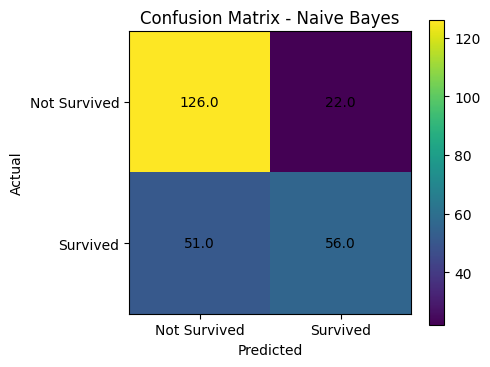

In [48]:
plt.style.use('default') 
plt.figure(figsize=(5, 4))
plt.imshow(nb_cm, interpolation='nearest')
plt.title("Confusion Matrix - Naive Bayes")
plt.colorbar()

plt.xticks([0, 1], ['Not Survived', 'Survived'])
plt.yticks([0, 1], ['Not Survived', 'Survived'])

for i in range(2):
    for j in range(2):
        plt.text(j, i, nb_cm[i, j],
                 ha="center", va="center")

plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.tight_layout()
plt.show()


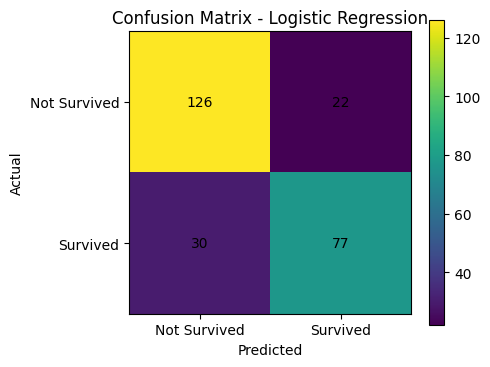

In [49]:
lr_cm = np.array(lr_cm)

plt.style.use('default') 
plt.figure(figsize=(5,4))
plt.imshow(lr_cm, interpolation='nearest')
plt.title("Confusion Matrix - Logistic Regression")
plt.colorbar()

labels = ['Not Survived', 'Survived']
tick_marks = np.arange(len(labels))

plt.xticks(tick_marks, labels)
plt.yticks(tick_marks, labels)

for i in range(2):
    for j in range(2):
        plt.text(j, i, int(lr_cm[i][j]), ha="center", va="center")
 
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.tight_layout()
plt.show()